# Health Data Analysis - Demonstration Notebook
**Course:** Software Development for Data Science  |  **Topic:** Healthcare and Public Health Data Analysis

This notebook demonstrates the application's modules step by step: **load -> inspect quality -> clean -> analyse -> visualise -> interpret**. It imports the same functions that `main.py` uses, so the notebook and the command-line tool can never disagree.

> **Data note:** the dataset is *simulated* (seeded generator, `seed=42`). No real patient is represented. See `DATA_ETHICS.md`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from health_analytics import analysis
from health_analytics.data_generator import generate_dataset
from health_analytics.data_loader import load_dataset
from health_analytics.preprocessing import preprocess_dataset, profile_data_quality
from health_analytics import visualization as viz

pd.set_option("display.max_columns", 20)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


## 1. Data input (Q2a)
The generator is deterministic: the same seed always produces the same file, which makes every result in this notebook reproducible.

In [2]:
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "patient_records.csv"
if not RAW_PATH.exists():
    generate_dataset(RAW_PATH, n_records=600, seed=42)

raw = load_dataset(RAW_PATH)
print(f"Shape: {raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head(8)

Shape: 615 rows x 13 columns


,patient_id,age,gender,region,smoker,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,diagnosis,annual_visits,visit_date
0,P0249,90,Male,East,No,28.7,124.0,75,193,92,Hypertension,2,2025-10-17
1,P0366,72,Female,North,Yes,23.4,125.0,77,239,92,Healthy,0,2025-09-05
2,P0433,46,Male,Central,No,17.8,127.0,80,218,65,Healthy,1,2025-10-11
3,P0076,59,MALE,North,No,24.4,132.0,88,186,88,Healthy,4,2025-10-05
4,P0133,58,Female,East,Yes,28.4,127.0,81,269,83,Heart Disease,10,2025-05-14
5,P0285,30,Male,West,Yes,28.0,110.0,70,198,90,Healthy,0,2025-01-16
6,P0189,26,Female,Central,No,33.4,121.0,78,170,89,Healthy,2,2025-11-24
7,P0003,60,Male,east,No,23.7,122.0,76,203,71,healthy,1,2025-02-28


## 2. Data-quality inspection (Q2b)
Before cleaning, we measure what is wrong. The generator deliberately injects realistic problems: blanks, duplicates, text in numeric fields, impossible values and inconsistent spellings.

In [3]:
profile = profile_data_quality(raw)
print("Duplicate rows :", profile["n_duplicate_rows"])
print("Total missing  :", sum(profile["missing_values"].values()))
print()
print("Missing values per column:")
print(pd.Series(profile["missing_values"]).loc[lambda s: s > 0].to_string())
print()
print("Data types (note 'object' where numbers are expected):")
print(raw[["age", "bmi", "glucose", "cholesterol"]].dtypes.to_string())

Duplicate rows : 15
Total missing  : 200

Missing values per column:
gender         30
smoker         30
bmi            36
systolic_bp    30
cholesterol    31
glucose        31
diagnosis      12

Data types (note 'object' where numbers are expected):
age                str
bmi            float64
glucose            str
cholesterol        str


In [4]:
print("Distinct spellings in 'gender':", sorted(raw["gender"].dropna().unique()))
print("Distinct spellings in 'smoker':", sorted(raw["smoker"].dropna().unique()))

Distinct spellings in 'gender': [' Female ', ' Male ', 'F', 'FEMALE', 'Female', 'M', 'MALE', 'Male', 'female', 'male']
Distinct spellings in 'smoker': [' No ', ' Yes ', 'N', 'NO', 'No', 'Y', 'YES', 'Yes', 'no', 'yes']


**Interpretation.** The extract contains duplicates, blanks in six columns, and numeric columns stored as text (`object`) because of entries such as `"unknown"` or `"N/A"`. Gender and smoker status appear in many spellings. Any statistic computed on this raw data would be wrong or would fail outright, so cleaning is a prerequisite.

## 3. Preprocessing (Q2b)
`preprocess_dataset` applies the documented order: coerce types -> standardise categories -> nullify impossible values -> de-duplicate -> drop rows lacking ID/diagnosis -> impute -> derive features.

In [5]:
clean, report = preprocess_dataset(raw)
print(f"Rows: {report['profile_before']['n_rows']} -> {report['profile_after']['n_rows']}")
print(f"Missing cells after cleaning: {sum(report['profile_after']['missing_values'].values())}\n")

audit = pd.Series({
    "duplicates removed": report["duplicates_removed"],
    "text entries -> missing": sum(report["coerced_to_missing"].values()),
    "impossible values nullified": sum(report["invalid_values_removed"].values()),
    "rows dropped (no ID/diagnosis)": report["rows_dropped_missing_key"],
    "values imputed (median/mode)": sum(report["values_imputed"].values()),
}, name="count")
audit.to_frame()

Rows: 615 -> 588
Missing cells after cleaning: 0



,count
duplicates removed,15
text entries -> missing,16
impossible values nullified,7
rows dropped (no ID/diagnosis),12
values imputed (median/mode),201


In [6]:
print(clean.dtypes.to_string())
clean.head()

patient_id                   str
age                        int64
gender                    object
region                    object
smoker                    object
bmi                      float64
systolic_bp                int64
diastolic_bp               int64
cholesterol                int64
glucose                    int64
diagnosis                 object
annual_visits              int64
visit_date        datetime64[us]
bmi_category                 str
age_group                    str
pulse_pressure             int64


,patient_id,age,gender,region,smoker,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,diagnosis,annual_visits,visit_date,bmi_category,age_group,pulse_pressure
0,P0249,90,Male,East,No,28.7,124,75,193,92,Hypertension,2,2025-10-17,Overweight,75+,49
1,P0366,72,Female,North,Yes,23.4,125,77,239,92,Healthy,0,2025-09-05,Normal,60-74,48
2,P0433,46,Male,Central,No,17.8,127,80,218,65,Healthy,1,2025-10-11,Underweight,45-59,47
3,P0076,59,Male,North,No,24.4,132,88,186,88,Healthy,4,2025-10-05,Normal,45-59,44
4,P0133,58,Female,East,Yes,28.4,127,81,269,83,Heart Disease,10,2025-05-14,Overweight,45-59,46


**Interpretation.** Every change is counted, giving an audit trail. Rows with no diagnosis are *dropped* rather than imputed, because inventing an outcome label would bias every diagnosis-based result. Other gaps are filled with the median (robust to skew) or mode, preserving sample size at the cost of slightly understated variance (a limitation noted in the report).

## 4. Statistical analysis (Q2c)

In [7]:
stats = analysis.summary_statistics(clean)
stats

,count,mean,median,std,min,q1,q3,max
age,588.0,47.82,48.0,15.10,18.0,37.0,57.0,90.0
bmi,588.0,26.60,26.5,4.43,15.0,23.6,29.7,38.3
systolic_bp,588.0,120.10,120.0,11.64,91.0,111.0,127.0,154.0
diastolic_bp,588.0,73.95,74.0,8.25,55.0,68.0,80.0,95.0
cholesterol,588.0,192.70,193.0,31.01,120.0,172.0,212.0,299.0
glucose,588.0,92.95,92.0,17.10,65.0,80.0,104.0,139.0
annual_visits,588.0,1.82,1.0,1.86,0.0,0.0,3.0,13.0


In [8]:
for col in ["diagnosis", "gender", "smoker", "bmi_category", "age_group"]:
    print(analysis.frequency_distribution(clean, col).to_string(), "\n")

               count  percent
diagnosis                    
Healthy          388    65.99
Diabetes          81    13.78
Hypertension      80    13.61
Heart Disease     39     6.63 

        count  percent
gender                
Female    313    53.23
Male      275    46.77 

        count  percent
smoker                
No        454    77.21
Yes       134    22.79 

              count  percent
bmi_category                
Overweight      243    41.33
Normal          179    30.44
Obese           140    23.81
Underweight      26     4.42 

           count  percent
age_group                
45-59        222    37.76
30-44        169    28.74
60-74         97    16.50
18-29         73    12.41
75+           27     4.59 



In [9]:
print("Mean / median / SD of systolic BP by diagnosis")
analysis.group_summary(clean, "diagnosis", "systolic_bp")

Mean / median / SD of systolic BP by diagnosis


,count,mean,median,std
diagnosis,,,,
Diabetes,81,124.38,123.0,12.00
Healthy,388,116.67,117.0,10.24
Heart Disease,39,125.92,125.0,11.67
Hypertension,80,129.55,130.0,9.92


In [10]:
print("Diagnosis mix (%) within each age group")
analysis.diagnosis_rate_by_group(clean, "age_group")

Diagnosis mix (%) within each age group


diagnosis,Diabetes,Healthy,Heart Disease,Hypertension
age_group,,,,
18-29,6.8,87.7,1.4,4.1
30-44,13.0,74.0,3.6,9.5
45-59,14.0,65.8,6.3,14.0
60-74,17.5,50.5,12.4,19.6
75+,22.2,14.8,22.2,40.7


In [11]:
outliers = analysis.detect_outliers_iqr(clean["cholesterol"])
print("Cholesterol IQR outliers:", outliers)
for finding in analysis.compute_key_findings(clean):
    print("-", finding)

Cholesterol IQR outliers: {'lower': 112.0, 'upper': 272.0, 'n_outliers': 2}
- The cleaned dataset holds 588 unique patients with a mean age of 47.8 years (median 48).
- 'Healthy' is the most frequent diagnosis (66.0% of patients).
- Smokers average +8.6 mg/dL cholesterol relative to non-smokers (199.3 vs 190.7).
- BMI and glucose are positively correlated (r = 0.40); age and systolic blood pressure show r = 0.60.
- Annual visits are highest for 'Heart Disease' (4.82 per year) and lowest for 'Healthy' (1.04).
- 23.8% of patients fall in the Obese BMI band.


**Interpretation.**
- Mean and median are close for age, BMI and blood pressure, indicating roughly symmetric distributions; `annual_visits` has mean > median, so it is right-skewed (a few heavy users).
- The share of *Healthy* patients falls steadily with age (from roughly 88 % in the 18-29 group to about 15 % at 75+), while hypertension and heart-disease shares rise.
- Systolic pressure is highest for Hypertension patients and lowest for Healthy ones, as clinical logic predicts.
- Heart-disease patients make the most visits per year; healthy patients the fewest.

## 5. Visualisation (Q2d)
Six charts are generated; each is saved to `output/figures/` and shown here. Colours follow a fixed, colour-blind-safe palette so each diagnosis keeps the same colour in every figure.

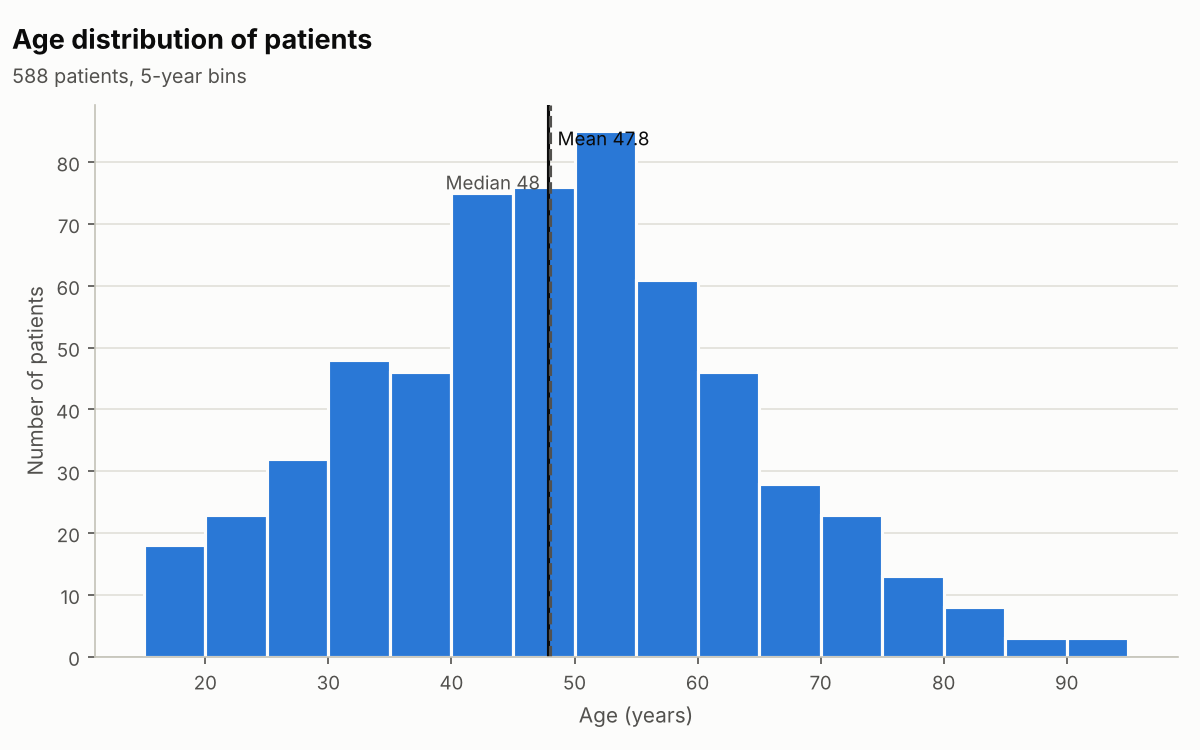

In [12]:
FIG_DIR = PROJECT_ROOT / "output" / "figures"
figures = viz.generate_all_figures(clean, FIG_DIR)
display(Image(filename=str(figures["age_distribution"])))

**Figure 1 - Age distribution.** Ages are approximately bell-shaped around 48 years, so a mean-based summary is reasonable. The cohort is working-age to middle-aged, with a thin older tail.

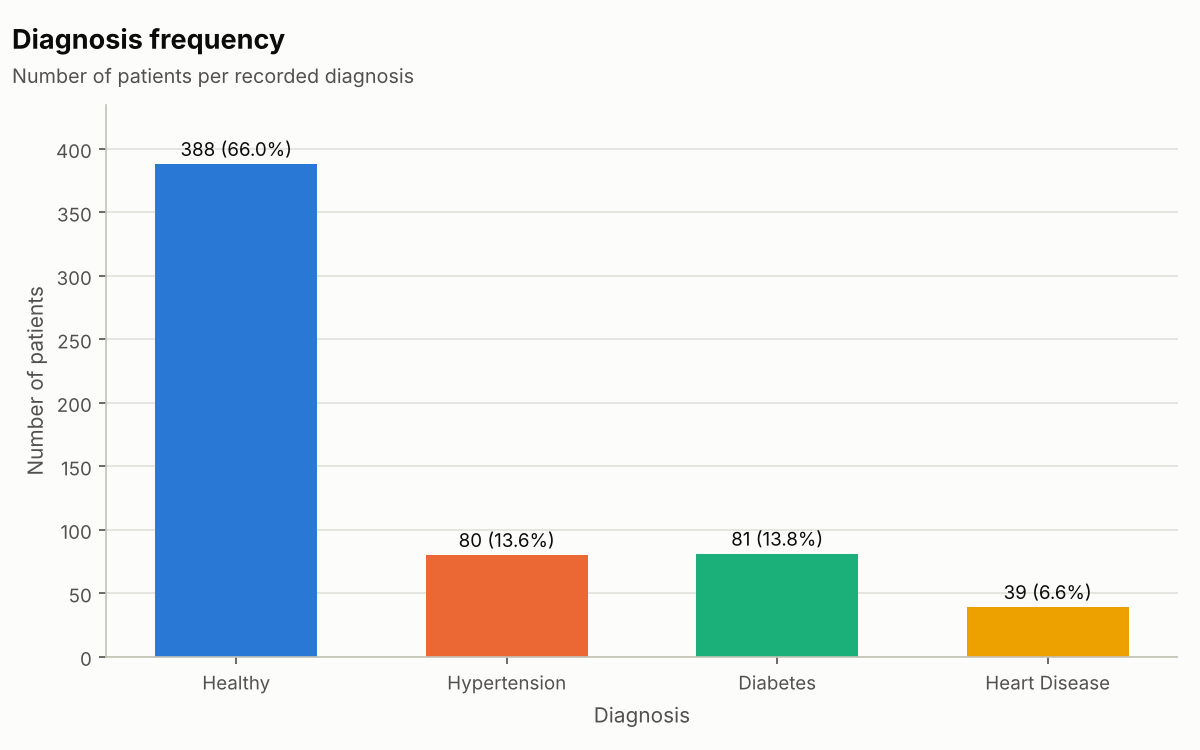

In [13]:
display(Image(filename=str(figures["diagnosis_frequency"])))

**Figure 2 - Diagnosis frequency.** Two-thirds of patients are healthy; diabetes and hypertension are about equally common; heart disease is rarest. This **class imbalance** matters for any future predictive model, since a naive classifier could reach about 66 % accuracy by always predicting *Healthy*.

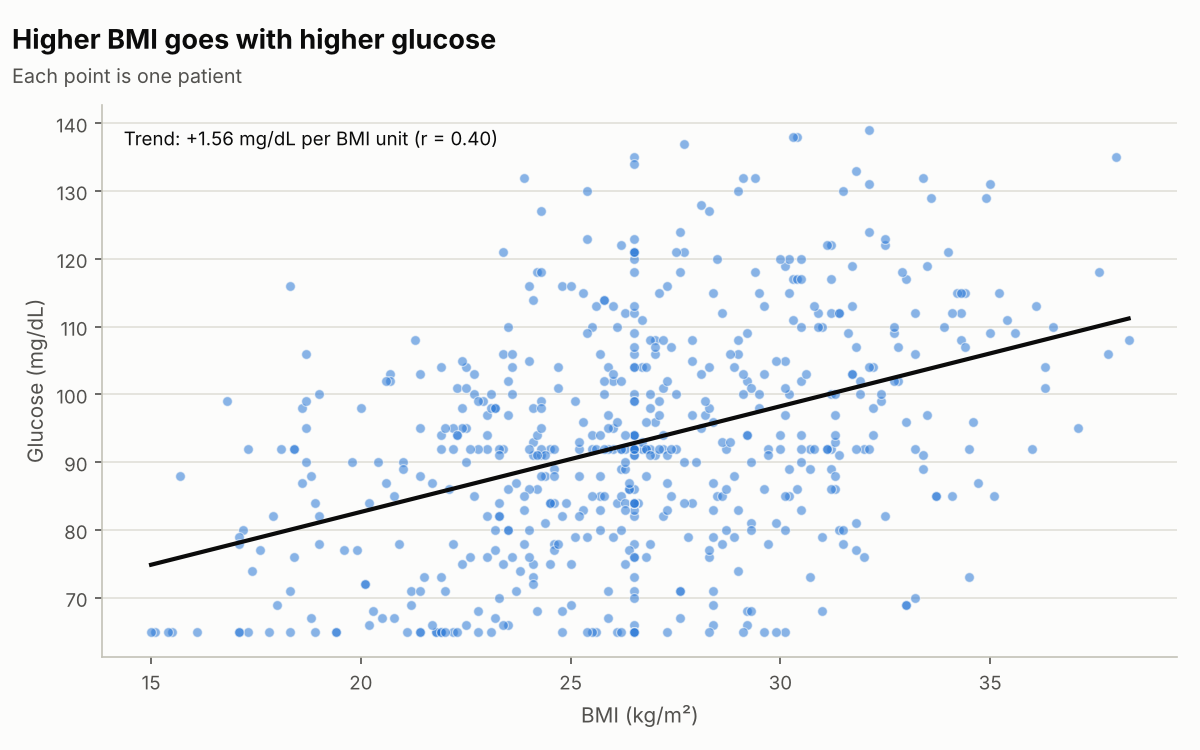

In [14]:
display(Image(filename=str(figures["bmi_vs_glucose"])))

**Figure 3 - BMI vs glucose.** A positive linear trend (r about 0.40): each extra BMI unit is associated with higher glucose. This is a *moderate* association with wide scatter, and correlation does not establish causation.

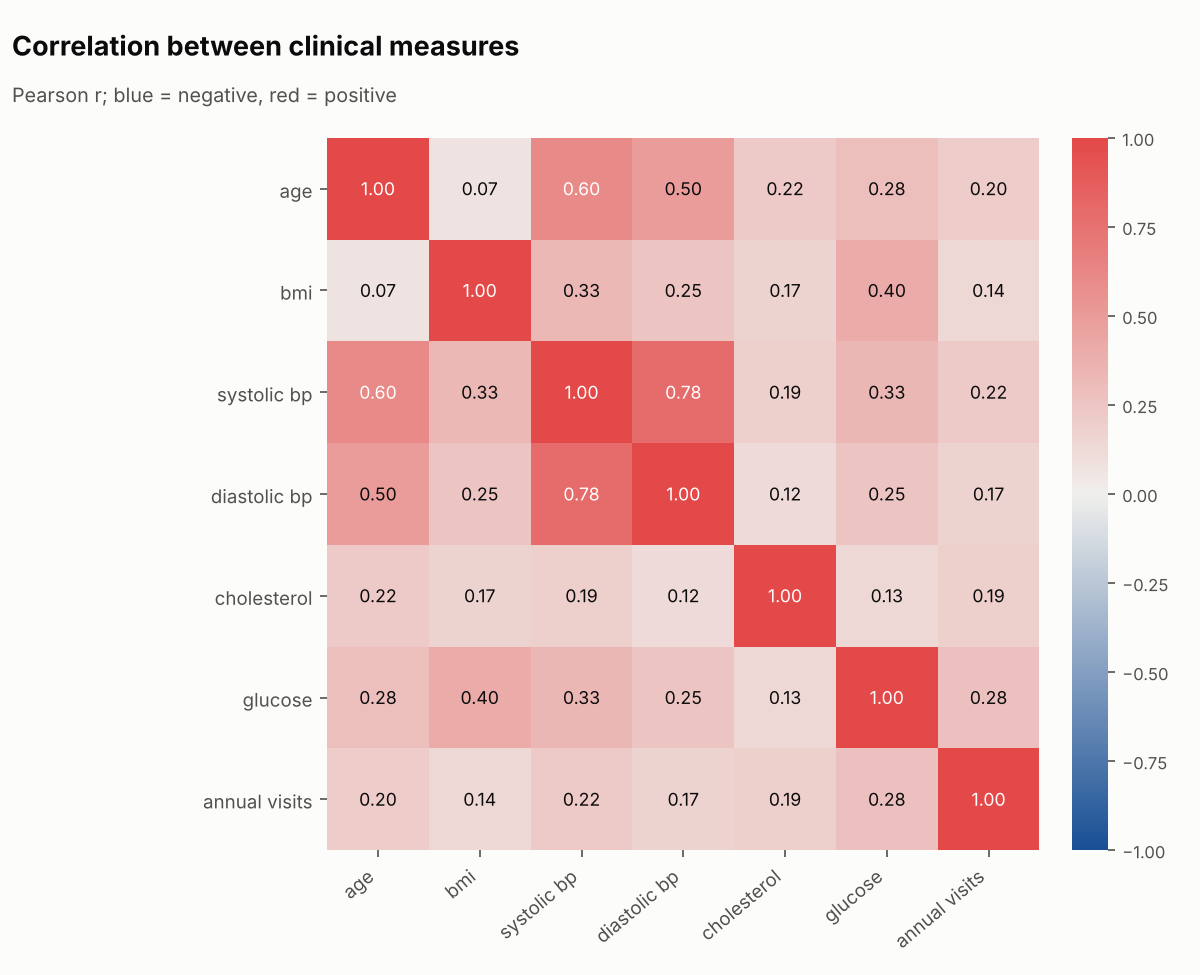

In [15]:
display(Image(filename=str(figures["correlation_heatmap"])))

**Figure 4 - Correlation heat map.** Age and systolic pressure are strongly related (r about 0.60) and systolic/diastolic are highly collinear (r about 0.78). Collinearity would need handling in a regression model.

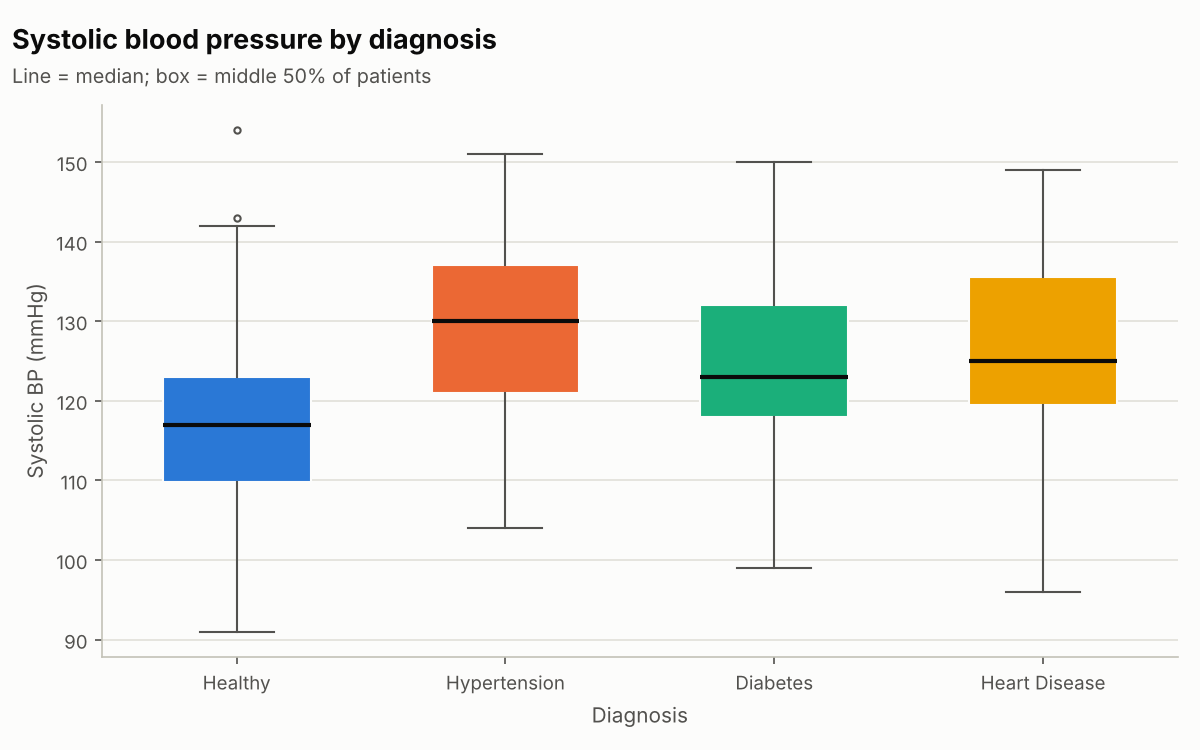

In [16]:
display(Image(filename=str(figures["bp_by_diagnosis"])))

**Figure 5 - Blood pressure by diagnosis.** The Hypertension median (about 130 mmHg) is roughly 13 mmHg above the Healthy median (about 117), and the two boxes barely overlap. Diabetes and Heart Disease sit in between. The groups overlap substantially in their whiskers, so blood pressure alone cannot separate diagnoses.

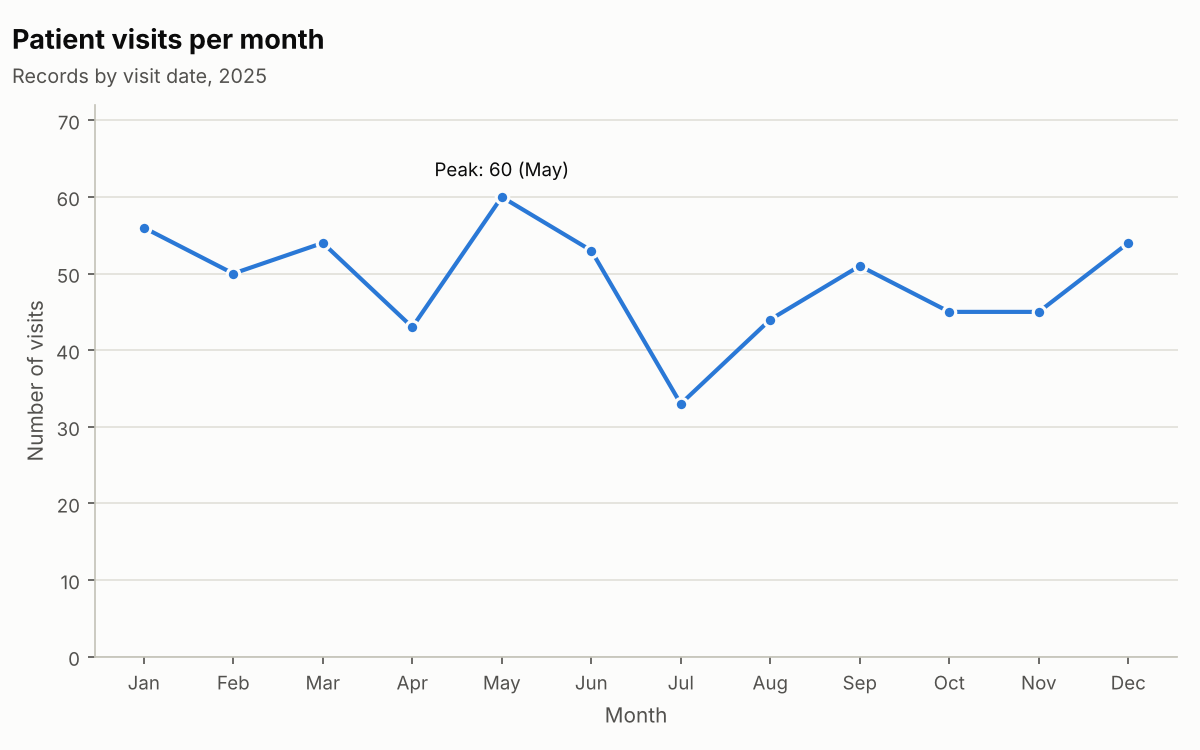

In [17]:
display(Image(filename=str(figures["monthly_visits"])))

**Figure 6 - Visits per month.** Counts range from 33 (July) to 60 (May) around a mean of about 49. Because visit dates were simulated uniformly, these swings are random sampling noise, not seasonality; real data would need a proper seasonal analysis.

## 6. Conclusions and limitations
**Conclusions**
1. A reproducible pipeline turned a messy extract into an analysis-ready dataset with a full audit trail.
2. Age, BMI and smoking status are associated with worse clinical measurements and more chronic diagnoses in this cohort.
3. Disease prevalence rises sharply with age.

**Limitations**
- Data are simulated from assumed relationships; the patterns are *built in*, so they validate the pipeline, not medical hypotheses.
- Imputation reduces variance; a real study would run sensitivity analyses.
- Correlations are descriptive and do not imply causation.

**Future work:** add a classification model with cross-validation, and a Streamlit dashboard for interactive exploration.